# Fase 1 · Etapa 1.4 — Consistência entre repetições e entre os dois acelerômetros

> **Bases de dados usadas:** **dados do pesquisador** — 144 registros da 2ª campanha.
> Nenhuma referência externa. (A 1ª campanha fica fora: um registro por configuração e
> C9 em aberto.)

Para cada configuração, cada repetição dá uma FRF de um registro (a/F, janela retangular,
10 ms de pré-impacto, mesmo comprimento para todas as repetições). Com o conjunto:
* **coerência entre repetições** γ²(f) — 1 se todas as repetições obedecem à mesma a = H·F.
  Cai com ruído, não linearidade, ponto de impacto variável ou vales do espectro de força.
  Registros saturados ficam fora da média do canal saturado;
* **picos** da FRF média onde γ² ≥ 0,8, e a **frequência de pico por repetição** (dispersão);
* **desvio de cada repetição** em relação à média: mediana de |20 log₁₀|Hᵢ/H̄|| na banda
  da força (dB). Repetição que destoa = candidata a outra montagem/ponto de impacto.

Estimador de EDA, não o da Fase 2: as coerências aqui são **limites inferiores** (sem
janelas, sem trigger refinado, impacto múltiplo incluído).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dampid.eda import consistency as cs
from dampid.io.catalog import load_catalog

cat = load_catalog("data/catalog.yaml")
sv = pd.read_csv("data/processed/fase1_survey.csv").set_index("id")
cfgs = ["LL_ACO", "LL_AL", "LL_ACRILICO", "LL_FIB_CARBONO", "LL_FIB_VIDRO_0", "LL_FIB_VIDRO_90",
        "LL_PLA_CAVERNA", "LL_PLA_LONGARINA_0", "LL_PLA_LONGARINA_90"]
f10 = sv.groupby("config").F_f10db_hz.median()
band = {c: (8.0 if "LONGARINA" in c else 20.0, float(min(1.5 * f10[c], 600.0))) for c in cfgs}
data = {c: cs.load_config(cat.by_config()[c]) for c in cfgs}
print({c: f"{data[c].n_seg / 25600:.2f} s, banda {band[c][0]:.0f}–{band[c][1]:.0f} Hz" for c in cfgs})

{'LL_ACO': '2.99 s, banda 20–283 Hz', 'LL_AL': '1.95 s, banda 20–236 Hz', 'LL_ACRILICO': '3.04 s, banda 20–600 Hz', 'LL_FIB_CARBONO': '2.79 s, banda 20–372 Hz', 'LL_FIB_VIDRO_0': '2.43 s, banda 20–225 Hz', 'LL_FIB_VIDRO_90': '2.83 s, banda 20–226 Hz', 'LL_PLA_CAVERNA': '3.35 s, banda 20–230 Hz', 'LL_PLA_LONGARINA_0': '1.82 s, banda 8–600 Hz', 'LL_PLA_LONGARINA_90': '1.36 s, banda 8–600 Hz'}


## 1. FRFs de todas as repetições e coerência entre repetições

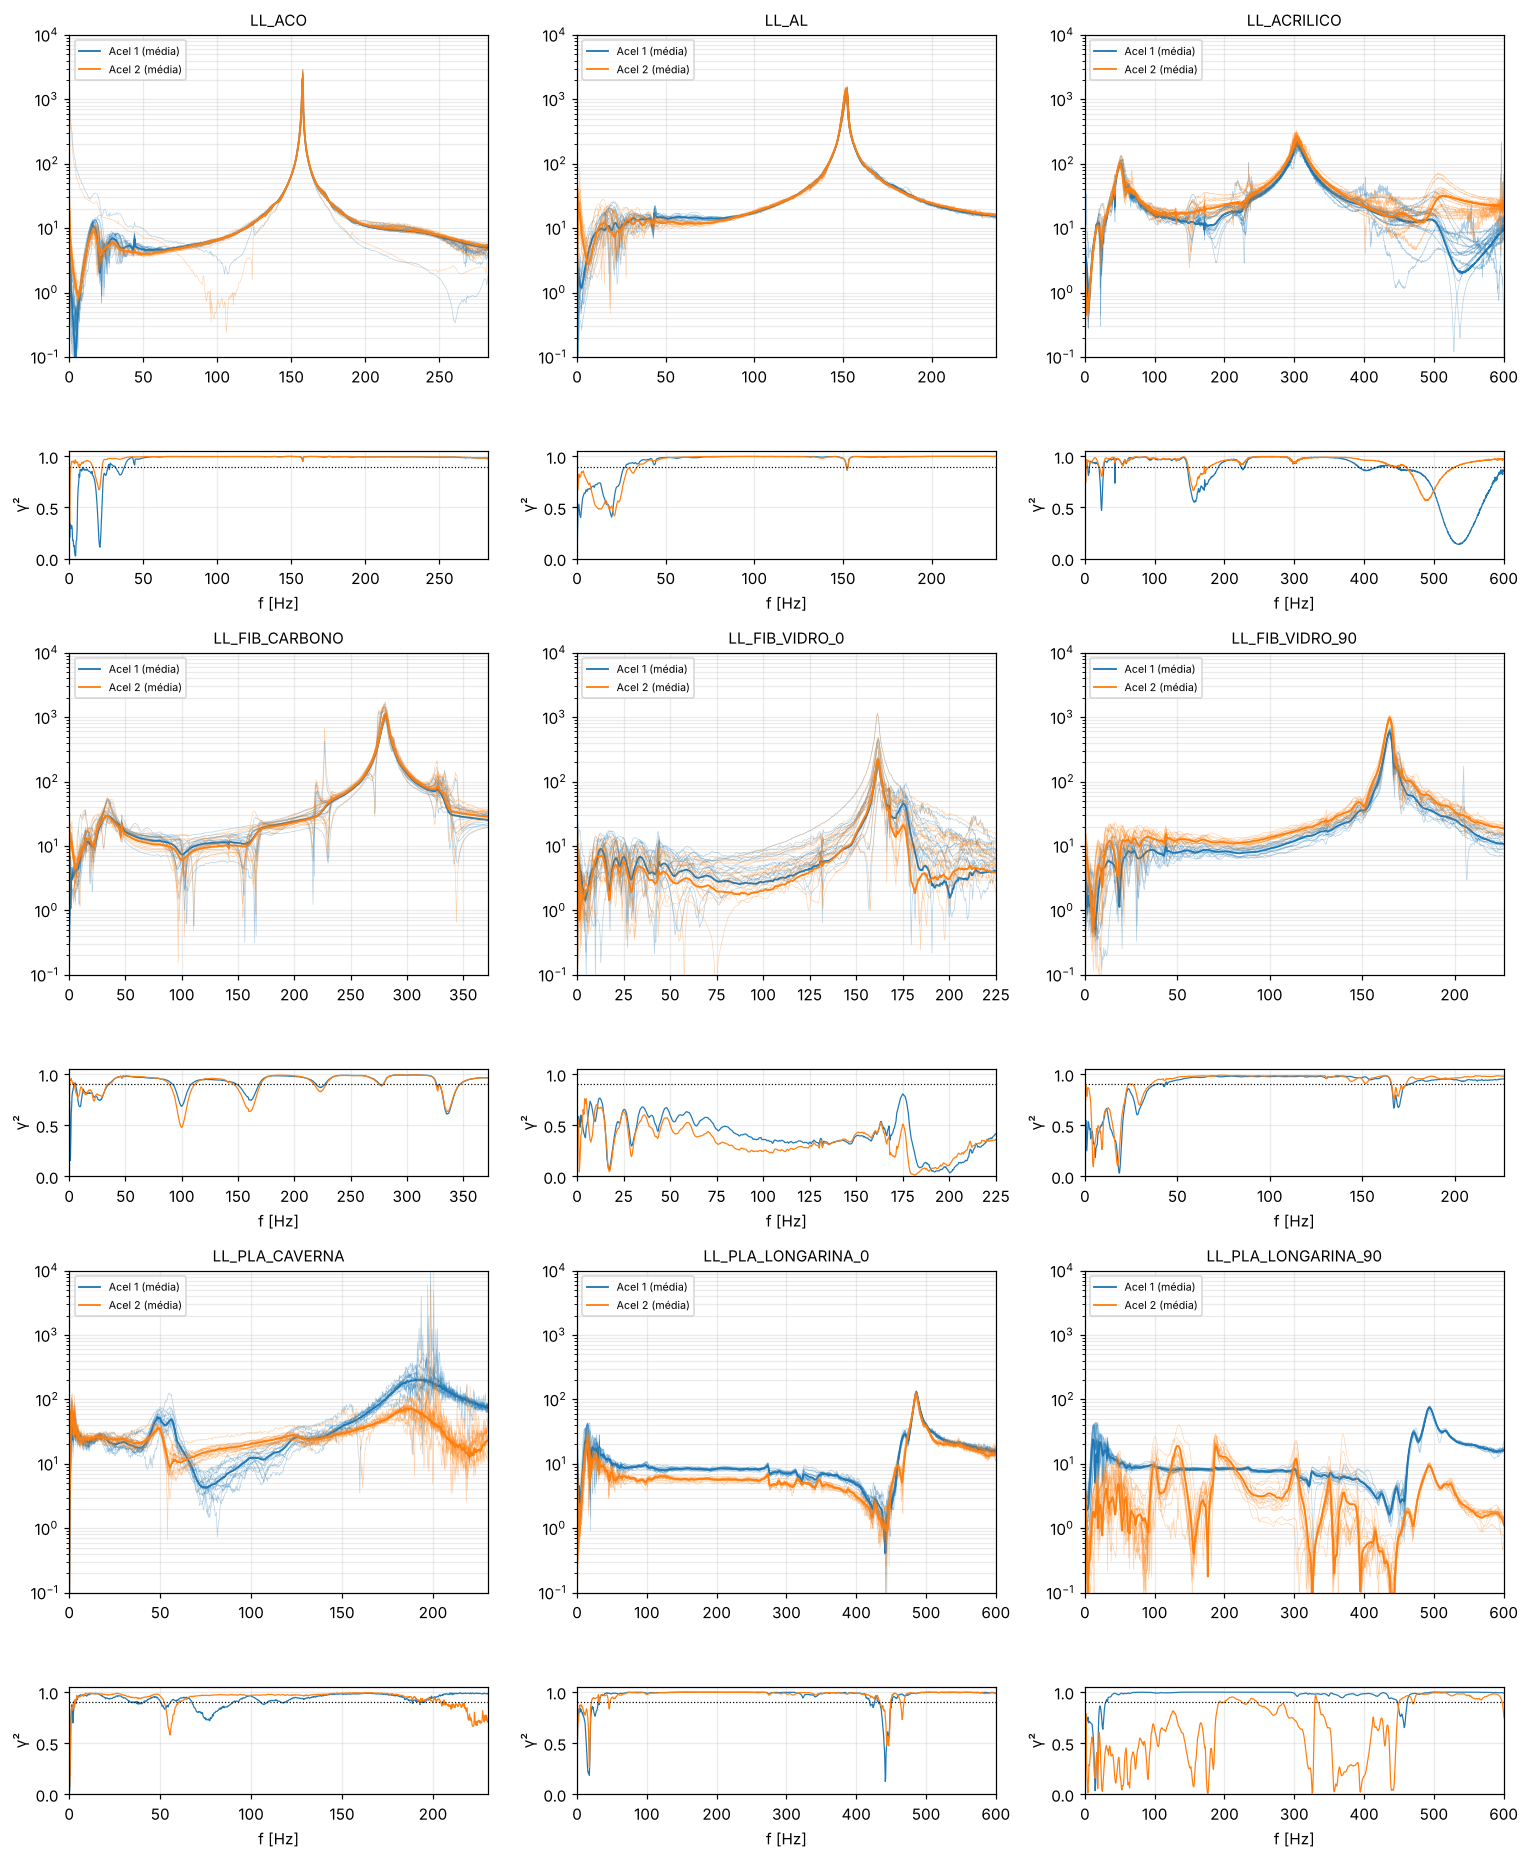

In [2]:
summary, per_rec, peaks_all = [], [], {}
fig, axs = plt.subplots(6, 3, figsize=(14, 17), gridspec_kw={"height_ratios": [3, 1] * 3})
for j, cfg in enumerate(cfgs):
    d = data[cfg]
    ax, axc = axs[2 * (j // 3), j % 3], axs[2 * (j // 3) + 1, j % 3]
    lo, hi = band[cfg]
    for ch in (0, 1):
        Hs = d.h_single(ch)
        for i in range(len(d.ids)):
            ax.semilogy(d.f_hz, np.abs(Hs[i]), color=f"C{ch}", lw=0.4, alpha=0.35)
        H1, coh = d.h1(ch)
        ax.semilogy(d.f_hz, np.abs(H1), color=f"C{ch}", lw=1.2, label=f"Acel {ch + 1} (média)")
        axc.plot(d.f_hz, coh, color=f"C{ch}", lw=0.8)
        pk = cs.ensemble_peaks(d.f_hz, H1, coh, (lo, hi))
        peaks_all[(cfg, ch)] = pk
        sel = (d.f_hz >= lo) & (d.f_hz <= hi)
        n_sat = int(d.clipped[ch].sum())
        fpk = {p: [cs.peak_frequency(d.f_hz, Hs[i], p) for i in range(len(d.ids))] for p in pk}
        summary.append({
            "config": cfg, "canal": f"Acel {ch + 1}",
            "rep. saturadas (fora da média)": n_sat if n_sat < len(d.ids) else "todas (média inclui)",
            "γ² mediana na banda": round(float(np.median(coh[sel])), 3),
            "fração da banda com γ² ≥ 0,9": round(float(np.mean(coh[sel] >= 0.9)), 2),
            "picos (γ² ≥ 0,8) [Hz]": ", ".join(f"{p:.1f}" for p in pk),
            "γ² nos picos": ", ".join(f"{coh[np.argmin(abs(d.f_hz - p))]:.3f}" for p in pk),
            "dispersão do pico principal [Hz] (min–máx)": (
                f"{min(fpk[pk[np.argmax([abs(H1[np.argmin(abs(d.f_hz - p))]) for p in pk])]]):.2f}–"
                f"{max(fpk[pk[np.argmax([abs(H1[np.argmin(abs(d.f_hz - p))]) for p in pk])]]):.2f}"
                if len(pk) else "—"),
        })
        for i, rid in enumerate(d.ids):
            row = {"id": rid, "config": cfg, "canal": ch,
                   "desvio_dB": cs.logmag_deviation(d.f_hz, Hs[i], H1, (lo, hi)),
                   "saturado": bool(d.clipped[ch][i])}
            for p in pk:
                row[f"fpk_{p:.0f}"] = fpk[p][i]
            per_rec.append(row)
    ax.set_xlim(0, hi)
    ax.set_ylim(1e-1, 1e4)
    ax.set_title(cfg, fontsize=10)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=7, loc="upper left")
    axc.set_xlim(0, hi)
    axc.set_ylim(0, 1.05)
    axc.axhline(0.9, color="k", ls=":", lw=0.8)
    axc.set_xlabel("f [Hz]")
    axc.set_ylabel("γ²")
    axc.grid(alpha=0.25)
plt.tight_layout()

In [3]:
summ = pd.DataFrame(summary)
with pd.option_context("display.width", 260, "display.max_colwidth", 60):
    print(summ.to_string(index=False))
summ.to_csv("docs/reports/fase1/05_consistencia_por_config.csv", index=False)

             config  canal rep. saturadas (fora da média)  γ² mediana na banda  fração da banda com γ² ≥ 0,9                  picos (γ² ≥ 0,8) [Hz]                             γ² nos picos dispersão do pico principal [Hz] (min–máx)
             LL_ACO Acel 1                              1                0.995                          0.95                      28.8, 44.2, 157.8                      0.918, 0.915, 0.951                              157.50–157.69
             LL_ACO Acel 2                              1                0.996                          0.99                            28.8, 157.8                             0.977, 0.950                              157.50–157.69
              LL_AL Acel 1                              1                0.997                          0.96                            31.8, 151.9                             0.932, 0.908                              151.31–152.38
              LL_AL Acel 2                              1               

## 2. Repetições que destoam
Critério descritivo (entra em D1.2): desvio de log-magnitude maior que
max(1,5 dB; 3 × mediana da configuração) no mesmo canal.

In [4]:
pr = pd.DataFrame(per_rec)
med = pr.groupby(["config", "canal"]).desvio_dB.transform("median")
pr["destoa"] = (pr.desvio_dB > np.maximum(1.5, 3 * med)) & ~pr.saturado
dev = pr.groupby(["config", "canal"]).desvio_dB.describe()[["50%", "max"]]
dev.columns = ["desvio mediano [dB]", "desvio máx [dB]"]
print(dev.round(2).to_string())
print("\nRepetições que destoam (canal não saturado):")
print(pr[pr.destoa][["id", "canal", "desvio_dB"]].round(2).to_string(index=False))
pr.to_csv("data/processed/fase1_consistency.csv", index=False)

                           desvio mediano [dB]  desvio máx [dB]
config              canal                                      
LL_ACO              0                     0.35             6.38
                    1                     0.32             6.74
LL_ACRILICO         0                     0.81             2.37
                    1                     0.61             2.32
LL_AL               0                     0.28             0.56
                    1                     0.28             0.51
LL_FIB_CARBONO      0                     0.83             3.01
                    1                     0.93             2.51
LL_FIB_VIDRO_0      0                     4.52            11.02
                    1                     5.09            12.72
LL_FIB_VIDRO_90     0                     1.16             2.02
                    1                     0.74             1.82
LL_PLA_CAVERNA      0                     1.10             2.87
                    1                   

## 3. Frequência do pico principal por repetição
Estimativa por parábola em log|H| (resolução Δf = fs/N). Dá a repetibilidade da montagem
— e é o primeiro número de referência para a Fase 5 (gate |Δf|/f < 1 %).

In [5]:
rows = []
for cfg in cfgs:
    for ch in (0, 1):
        sub = pr[(pr.config == cfg) & (pr.canal == ch) & ~pr.saturado]
        for col in [c for c in sub.columns if c.startswith("fpk_")]:
            v = sub[col].dropna()
            if len(v) < 3:
                continue
            rows.append({"config": cfg, "canal": f"Acel {ch + 1}", "pico ~ [Hz]": col[4:],
                         "n": len(v), "média [Hz]": round(v.mean(), 2), "dp [Hz]": round(v.std(), 3),
                         "dp/média [%]": round(100 * v.std() / v.mean(), 3)})
fp = pd.DataFrame(rows)
with pd.option_context("display.width", 200):
    print(fp.to_string(index=False))
fp.to_csv("docs/reports/fase1/05_frequencias_pico.csv", index=False)

             config  canal pico ~ [Hz]  n  média [Hz]  dp [Hz]  dp/média [%]
             LL_ACO Acel 1          29 15       29.06    0.583         2.005
             LL_ACO Acel 1          44 15       44.09    0.307         0.697
             LL_ACO Acel 1         158 15      157.62    0.053         0.034
             LL_ACO Acel 2          29 15       27.70    3.684        13.298
             LL_ACO Acel 2         158 15      157.62    0.054         0.034
              LL_AL Acel 1          32 15       52.63   74.599       141.742
              LL_AL Acel 1         152 15      152.01    0.351         0.231
              LL_AL Acel 2         152 15      152.01    0.352         0.231
        LL_ACRILICO Acel 1          42 11       42.06    0.126         0.299
        LL_ACRILICO Acel 1          51 11       51.03    0.526         1.031
        LL_ACRILICO Acel 1         304 11      303.35    2.833         0.934
        LL_ACRILICO Acel 2          42 11       42.05    0.121         0.287

## 4. Acelerômetro 1 × Acelerômetro 2
Razão |H_Acel2 / H_Acel1| das FRFs médias. Razão ≈ 1 em toda a banda = sensores em pontos
equivalentes por simetria (ou muito próximos); picos que só aparecem num canal = modo com
nó no outro sensor ou com movimento em outra direção (ex.: fibra de vidro a 90°).

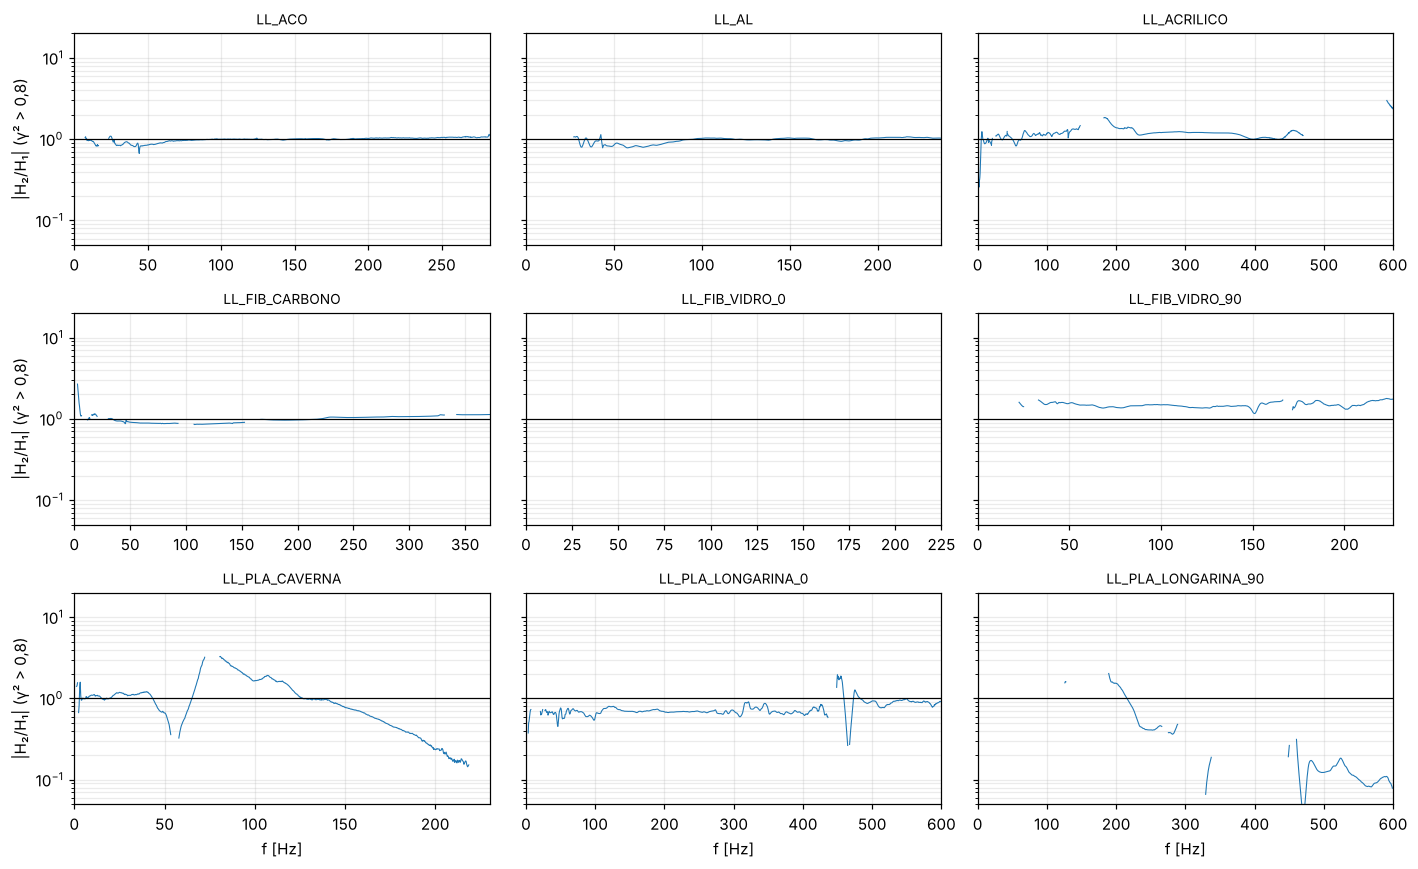

In [6]:
fig, axs = plt.subplots(3, 3, figsize=(13, 8), sharey=True)
for ax, cfg in zip(axs.ravel(), cfgs, strict=True):
    d = data[cfg]
    H0, c0 = d.h1(0)
    H1_, c1_ = d.h1(1)
    ok = (c0 > 0.8) & (c1_ > 0.8)
    ratio = np.abs(H1_ / H0)
    ax.semilogy(d.f_hz, np.where(ok, ratio, np.nan), lw=0.7)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_xlim(0, band[cfg][1])
    ax.set_ylim(0.05, 20)
    ax.set_title(cfg, fontsize=9)
    ax.grid(True, which="both", alpha=0.25)
for ax in axs[-1]:
    ax.set_xlabel("f [Hz]")
for ax in axs[:, 0]:
    ax.set_ylabel("|H₂/H₁| (γ² > 0,8)")
plt.tight_layout()

## 5. O ponto de impacto foi o mesmo em todas as repetições?
O sinal da parte real de a/F na linha de massa (abaixo do 1º modo elástico) depende do
produto x_f·x_r (Etapa 1.2). Se ele **troca de sinal** entre repetições do mesmo canal, o
ponto de impacto (ou o sensor) mudou. Contagem de repetições com Re(H) > 0 na faixa da
linha de massa usada na Etapa 1.2:

In [7]:
ml_band = {"LL_ACRILICO": (10, 20), "LL_PLA_LONGARINA_0": (60, 200), "LL_PLA_LONGARINA_90": (60, 200),
           "LL_PLA_CAVERNA": (20, 40)}
rows = []
for cfg in cfgs:
    d = data[cfg]
    b = ml_band.get(cfg, (30, 70))
    sel = (d.f_hz >= b[0]) & (d.f_hz <= b[1])
    row = {"config": cfg, "faixa [Hz]": b}
    for ch in (0, 1):
        s = np.median(np.cos(np.angle(d.h_single(ch)[:, sel])), axis=1)
        row[f"Acel {ch + 1}: Re>0 / n"] = f"{int(np.sum(s > 0))}/{len(s)}"
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

             config faixa [Hz] Acel 1: Re>0 / n Acel 2: Re>0 / n
             LL_ACO   (30, 70)             0/16             0/16
              LL_AL   (30, 70)             0/16             0/16
        LL_ACRILICO   (10, 20)            16/16            16/16
     LL_FIB_CARBONO   (30, 70)            16/16            16/16
     LL_FIB_VIDRO_0   (30, 70)            15/16            13/16
    LL_FIB_VIDRO_90   (30, 70)             0/16             0/16
     LL_PLA_CAVERNA   (20, 40)             0/16             0/16
 LL_PLA_LONGARINA_0  (60, 200)             0/16             0/16
LL_PLA_LONGARINA_90  (60, 200)             0/16             2/16
